In [125]:
import numpy as np
import matplotlib.pyplot as plt

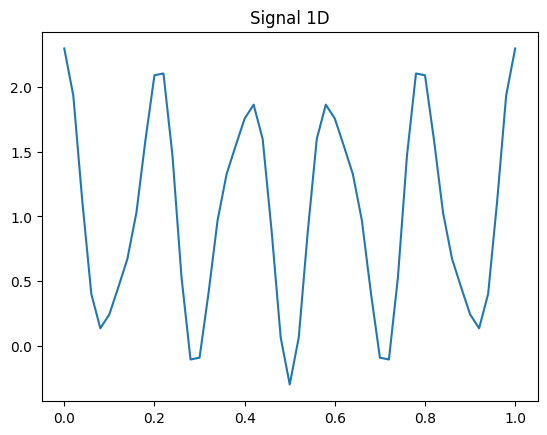

In [127]:
SR = 50  
SP = 1 / SR 

t = np.arange(0, 1 + SP, SP) 

s = 1 + np.cos(2 * np.pi * 5 * t) + 0.3 * np.cos(2 * np.pi * 9 * t)

plt.plot(t, s)
plt.title("Signal 1D")
plt.show()

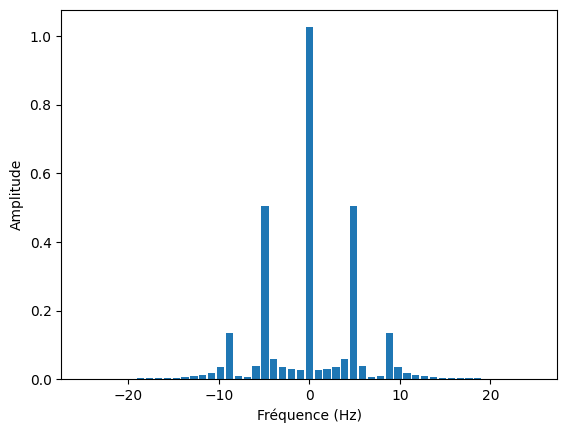

In [129]:
import ressources
ressources.fourier1D(s, SR)

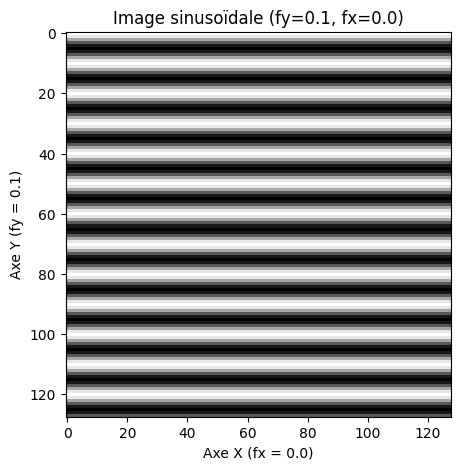

In [167]:
import matplotlib.pyplot as plt
import ressources
import importlib

importlib.reload(ressources)

n = 128
m = 128

fy = 0.1  
fx = 0.0  

img_vertical = ressources.wave(n, m, fy, fx)

plt.figure(figsize=(5, 5))
plt.imshow(img_vertical, cmap='gray')
plt.title("Image sinusoïdale (fy=0.1, fx=0.0)")
plt.xlabel('Axe X (fx = 0.0)')
plt.ylabel('Axe Y (fy = 0.1)')
plt.show()

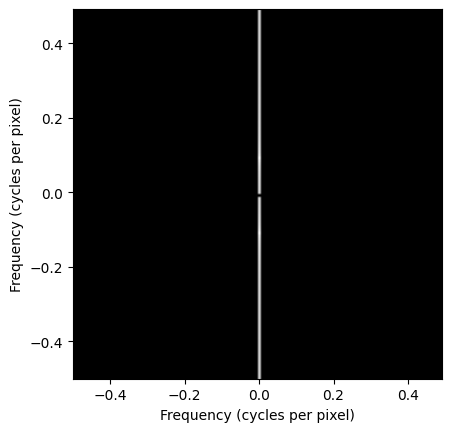

In [133]:
# 2.2 Calcul et affichage du spectre de Fourier de l'image verticale
ressources.fourier2d_all(img_vertical)

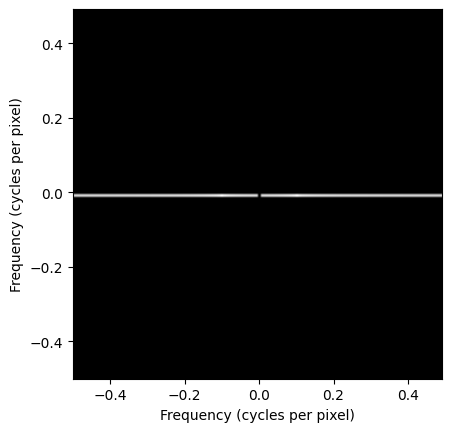

In [169]:
fy_horiz = 0.0  
fx_horiz = 0.1  

img_horizontal = ressources.wave(n, m, fy_horiz, fx_horiz)

ressources.fourier2d_all(img_horizontal)

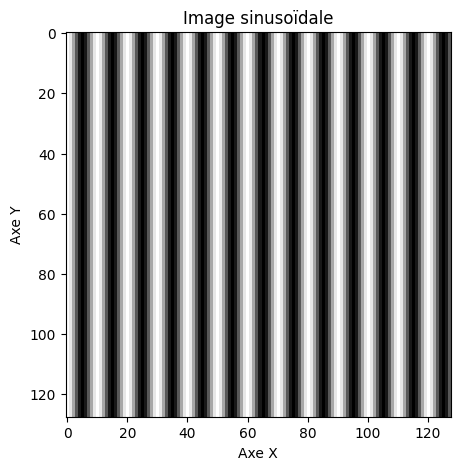

In [137]:
plt.figure(figsize=(5, 5))
plt.imshow(img_horizontal, cmap='gray')
plt.title("Image sinusoïdale")
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.show()

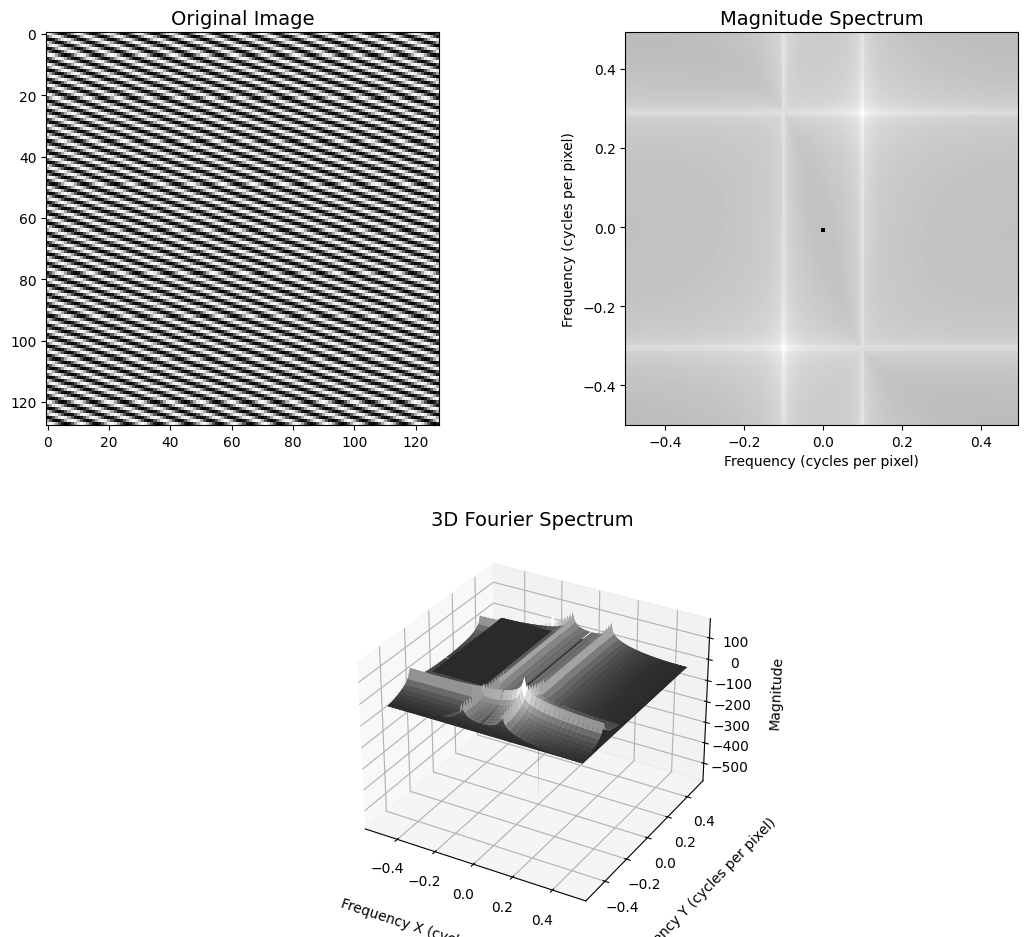

In [139]:
import importlib
import ressources

importlib.reload(ressources)

n, m = 128, 128
fy_mixte = 0.3
fx_mixte = 0.1

img_mixte = ressources.wave(n, m, fy_mixte, fx_mixte)
ressources.fourier2d_all(img_mixte)

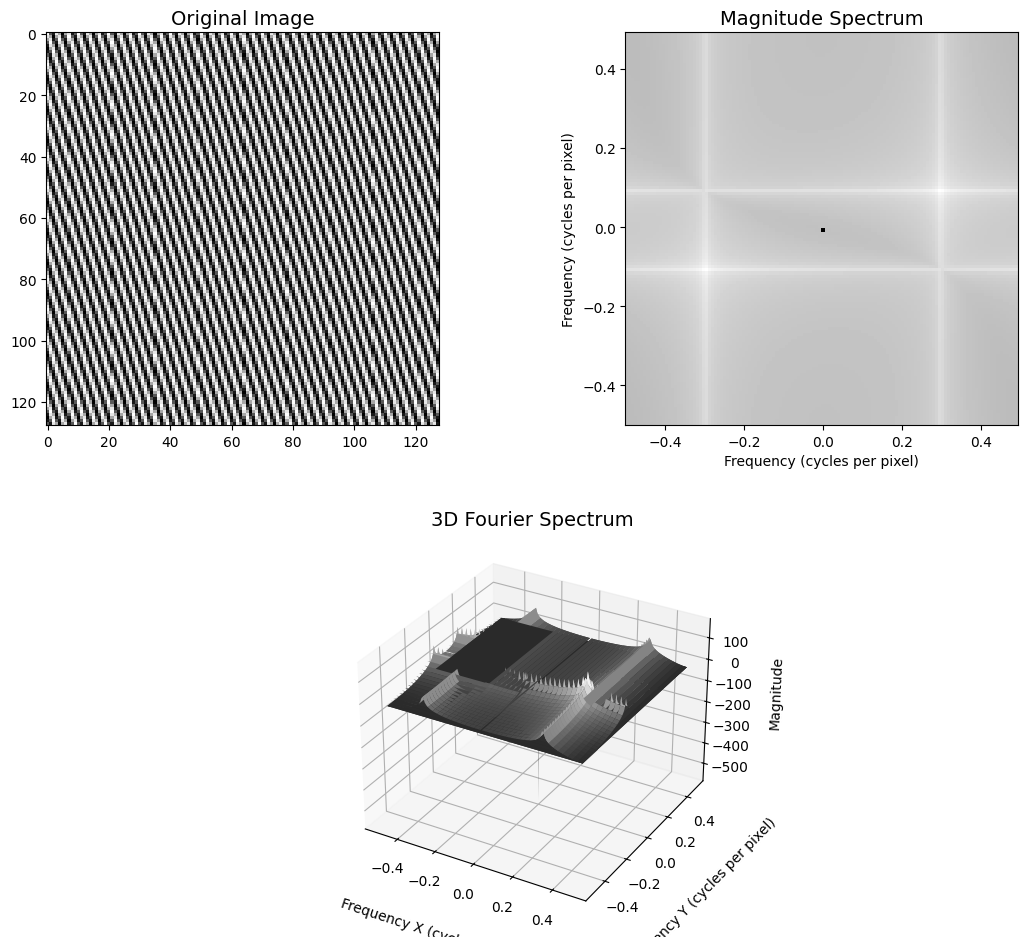

In [141]:
import importlib
import ressources

importlib.reload(ressources)

n, m = 128, 128
fy_mixte = 0.1
fx_mixte = 0.3

img_mixte = ressources.wave(n, m, fy_mixte, fx_mixte)
ressources.fourier2d_all(img_mixte)


--- Analyse de l'image synthétique : eau.bmp ---


C:\Users\USER\OneDrive\Bureau\traitement d'image\tp3\ressources 2\ressources.py:85: RuntimeWarning: divide by zero encountered in log
  # Affichage du spectre de fourrier
C:\Users\USER\OneDrive\Bureau\traitement d'image\tp3\ressources 2\ressources.py:110: RuntimeWarning: divide by zero encountered in log
  # Détection des fréqunces dominantes le long de x et y


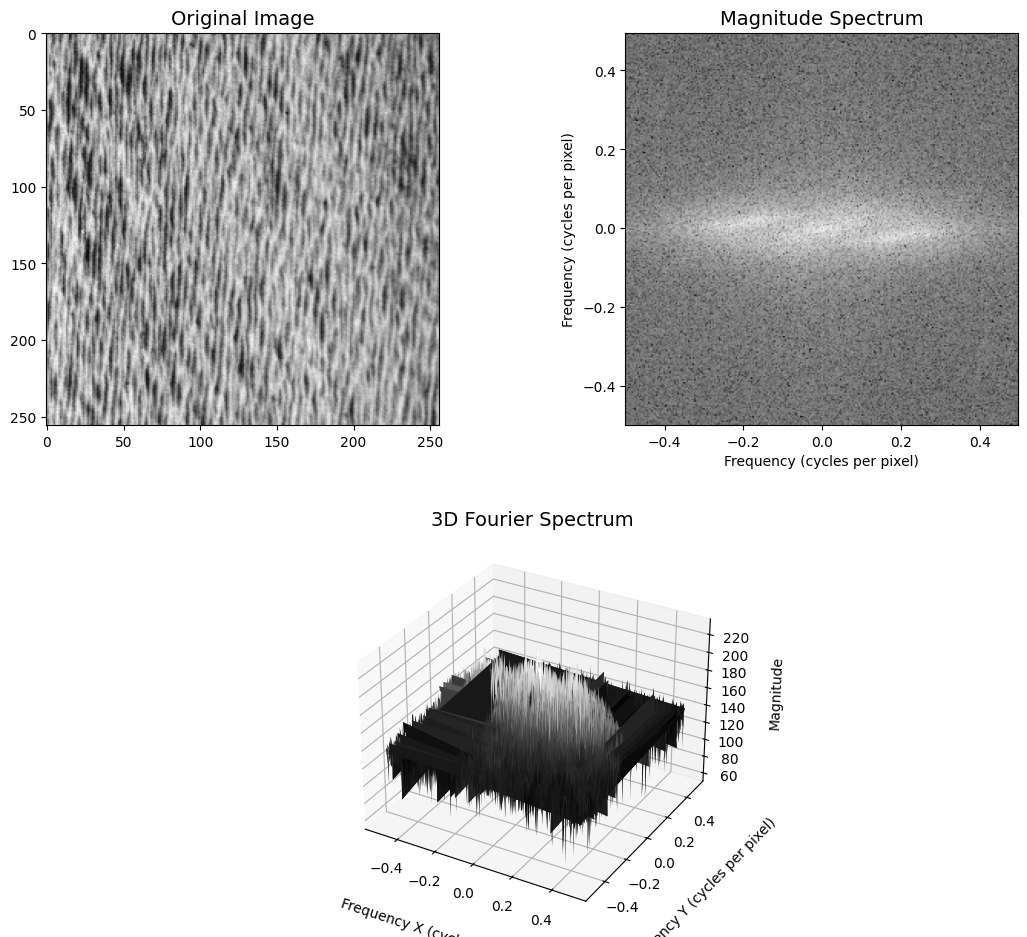


--- Analyse de l'image synthétique : oval0.bmp ---


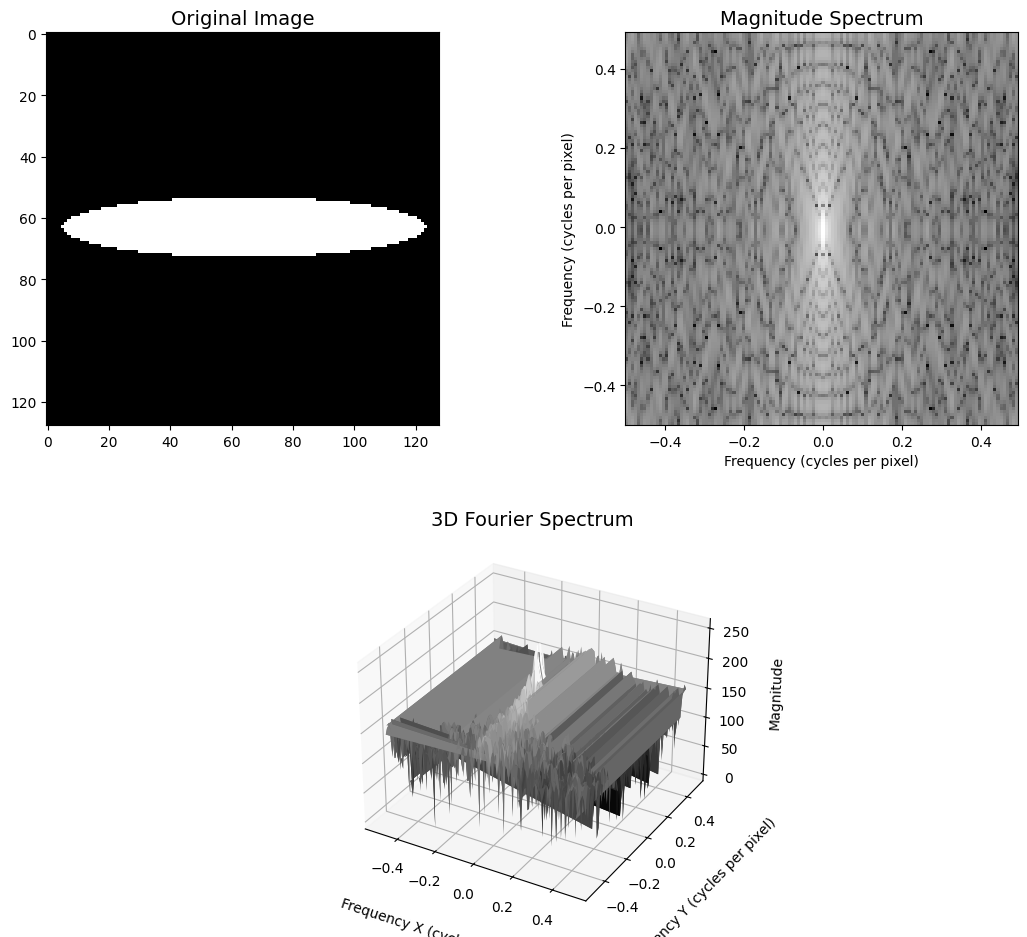


--- Analyse de l'image synthétique : oval2.bmp ---


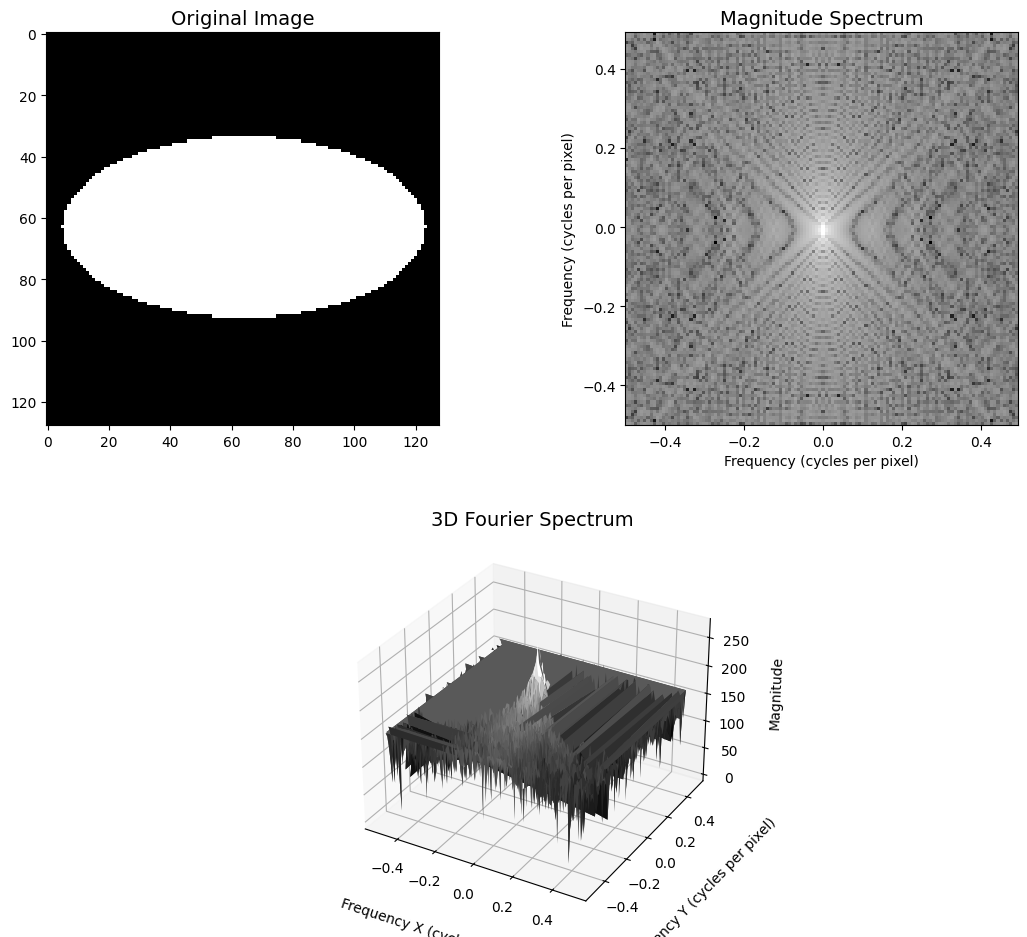


--- Analyse de l'image synthétique : oval3.bmp ---


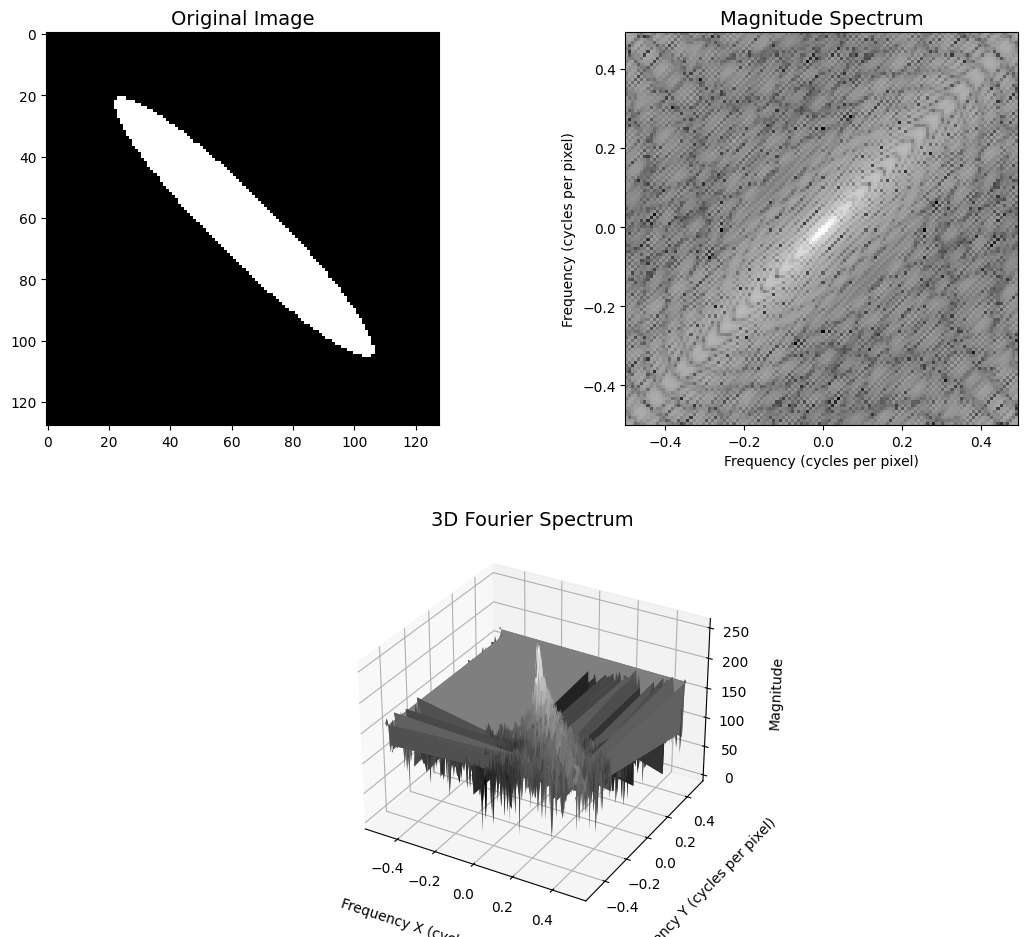


--- Analyse de l'image synthétique : oval5.bmp ---


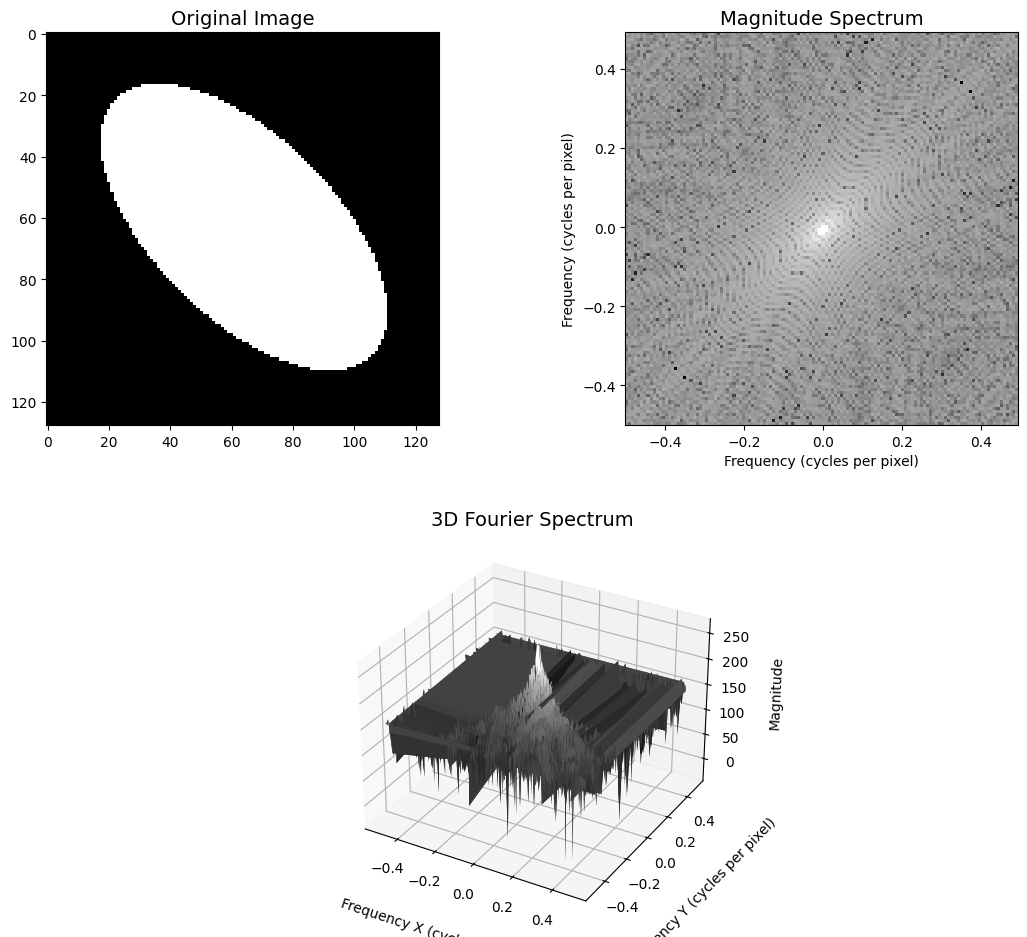


--- Analyse de l'image synthétique : oval6.bmp ---


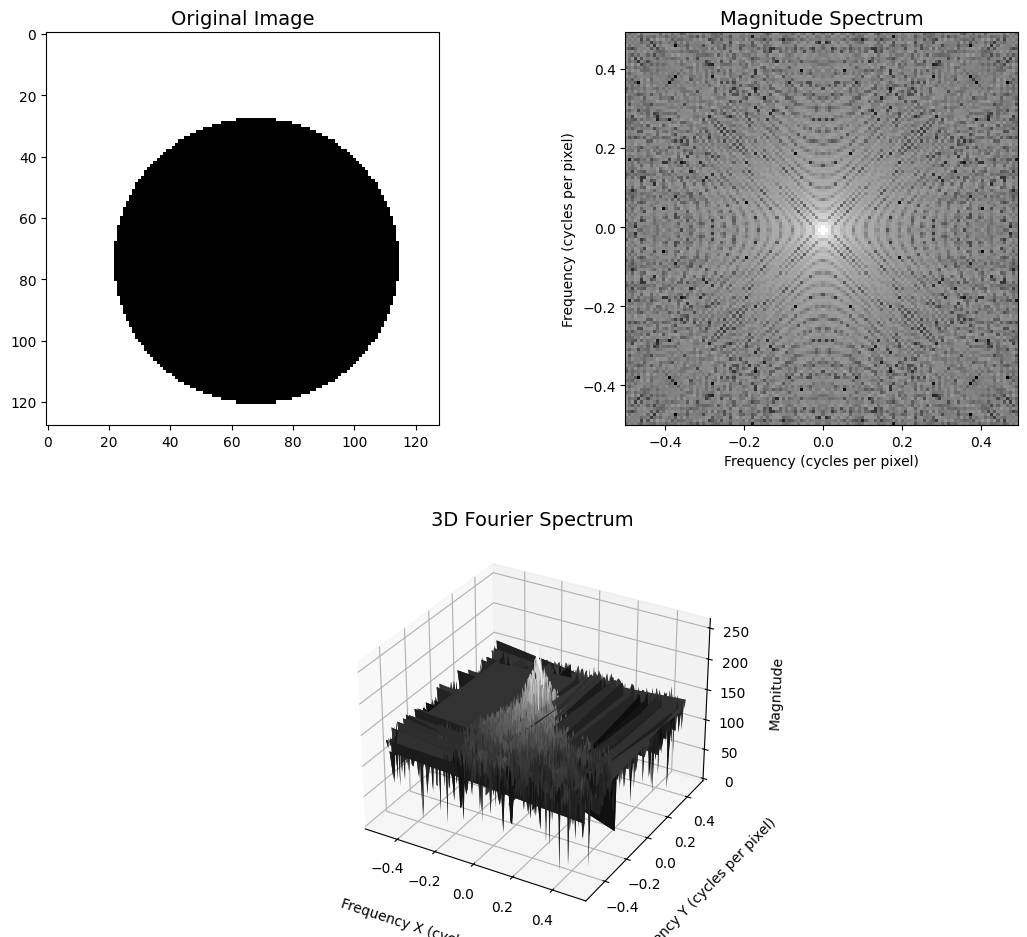


--- Analyse de l'image synthétique : rupt0.bmp ---


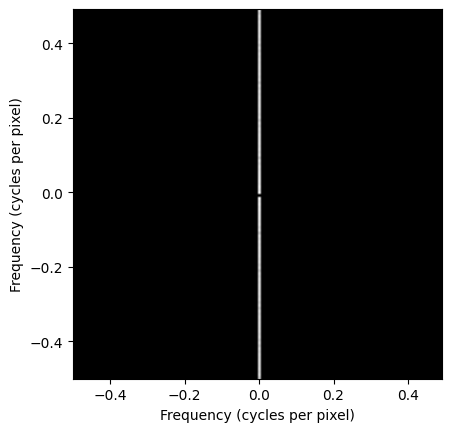


--- Analyse de l'image synthétique : sable.bmp ---


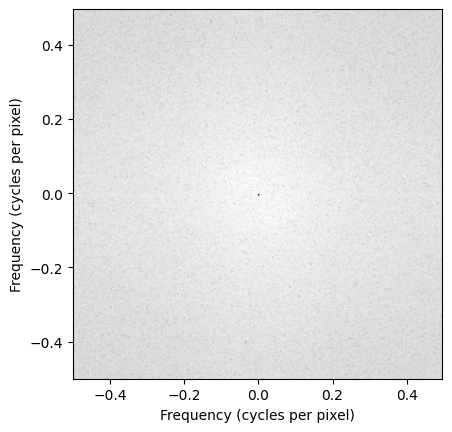

In [163]:
import os
import matplotlib.pyplot as plt
import ressources

dossier = r"C:\Users\USER\OneDrive\Bureau\traitement d'image\tp3\ressources 2\synthetic_images"

try:
    fichiers = os.listdir(dossier)
    images = [f for f in fichiers if f.lower().endswith(('.bmp', '.jpg', '.jpeg'))]
    
    if not images:
        print("Aucune image trouvée dans le dossier.")
    
    for nom_img in images:
        print(f"\n--- Analyse de l'image synthétique : {nom_img} ---")
        
        chemin_complet = os.path.join(dossier, nom_img)
        img = plt.imread(chemin_complet)
        
        if len(img.shape) == 3:
            img = img.mean(axis=2)
            
        ressources.fourier2d_all(img)

except Exception as e:
    print(f"Une erreur est survenue : {e}")

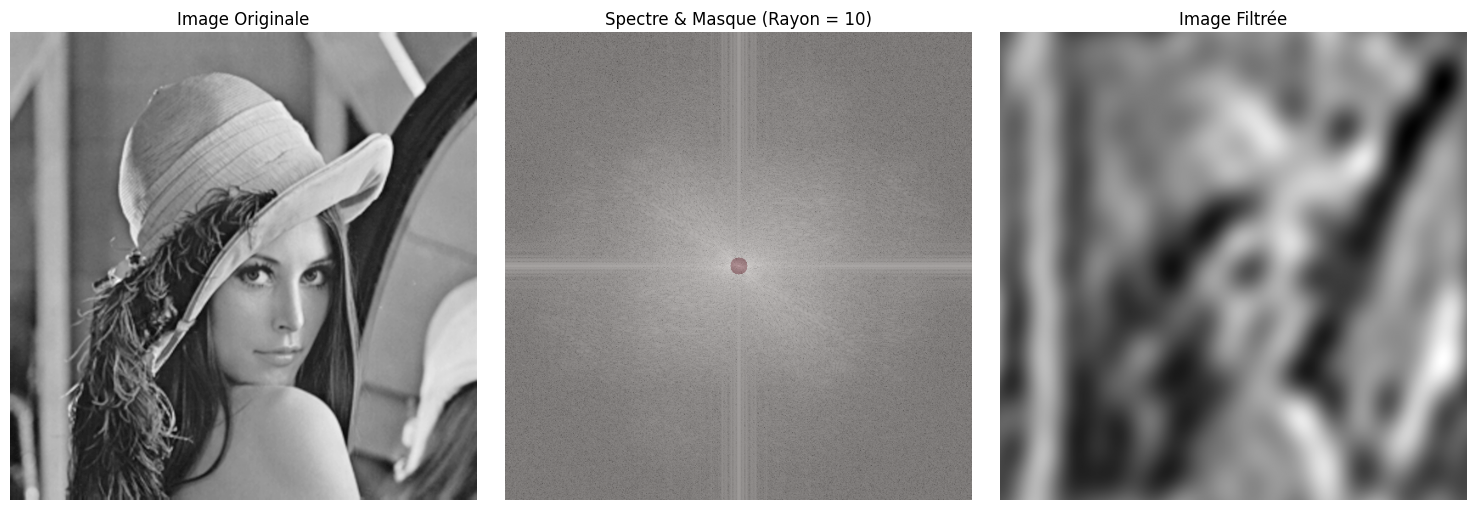

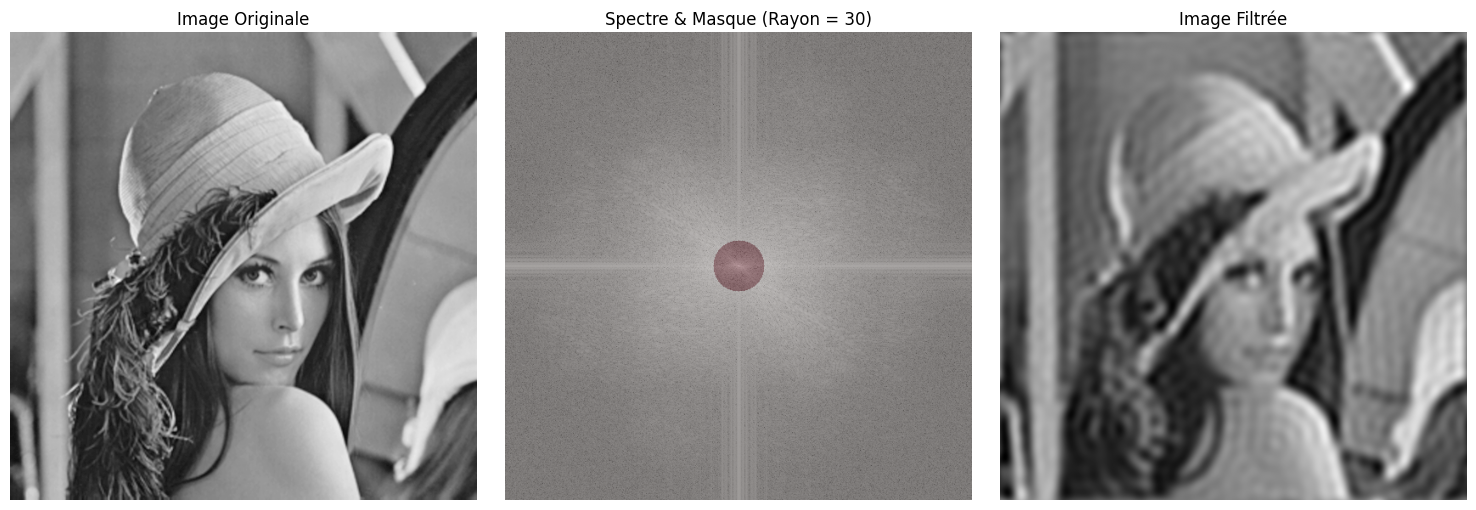

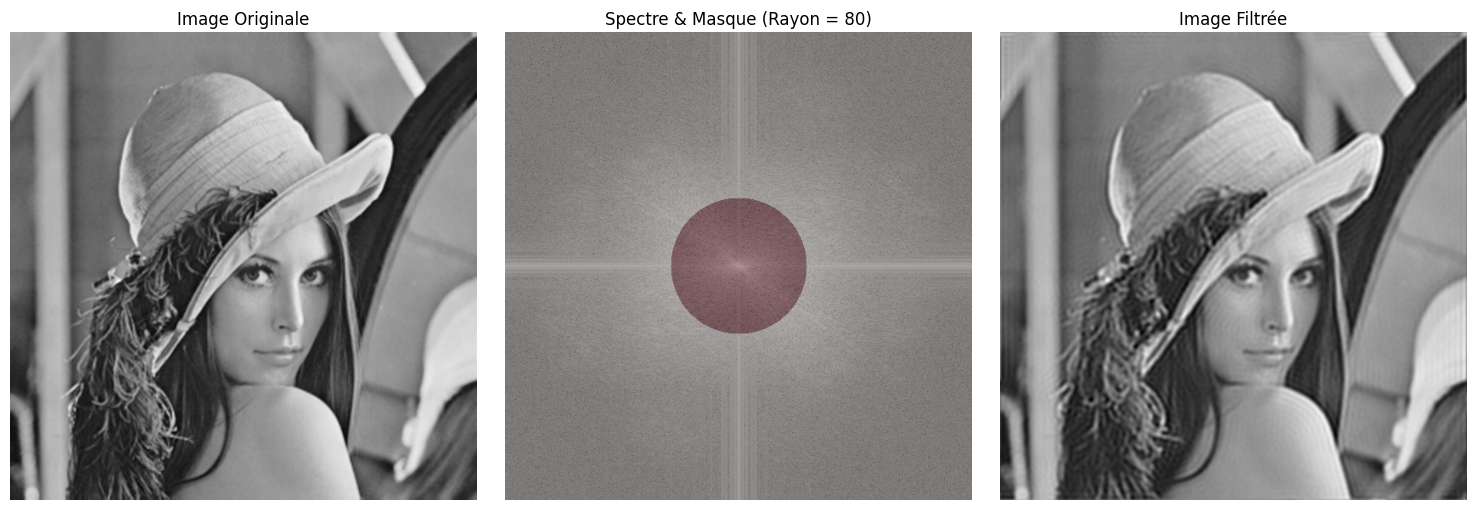

In [161]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

def filtrage_passe_bas_ideal(img, rayon):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2  
    
    y, x = np.ogrid[:rows, :cols]
    distance_carre = (x - ccol)**2 + (y - crow)**2
    
    masque = np.zeros((rows, cols))
    masque[distance_carre <= rayon**2] = 1
    
    fshift_filtre = fshift * masque
    
    f_ishift = np.fft.ifftshift(fshift_filtre) 
    img_filtree = np.abs(np.fft.ifft2(f_ishift)) 
    
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    
    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('Image Originale')
    axes[0].axis('off')
    
    spectre_magnitude = 20 * np.log(np.abs(fshift) + 1) 
    axes[1].imshow(spectre_magnitude, cmap='gray')
    axes[1].imshow(masque, cmap='Reds', alpha=0.3) 
    axes[1].set_title(f'Spectre & Masque (Rayon = {rayon})')
    axes[1].axis('off')
    
    axes[2].imshow(img_filtree, cmap='gray')
    axes[2].set_title('Image Filtrée')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()


lena = cv2.imread('Lena_nv.png', cv2.IMREAD_GRAYSCALE) 

if lena is not None:
    filtrage_passe_bas_ideal(lena, rayon=10)  
    filtrage_passe_bas_ideal(lena, rayon=30)  
    filtrage_passe_bas_ideal(lena, rayon=80)  
else:
    print("Erreur : Impossible de charger Lena.png. Vérifie le chemin du fichier !")

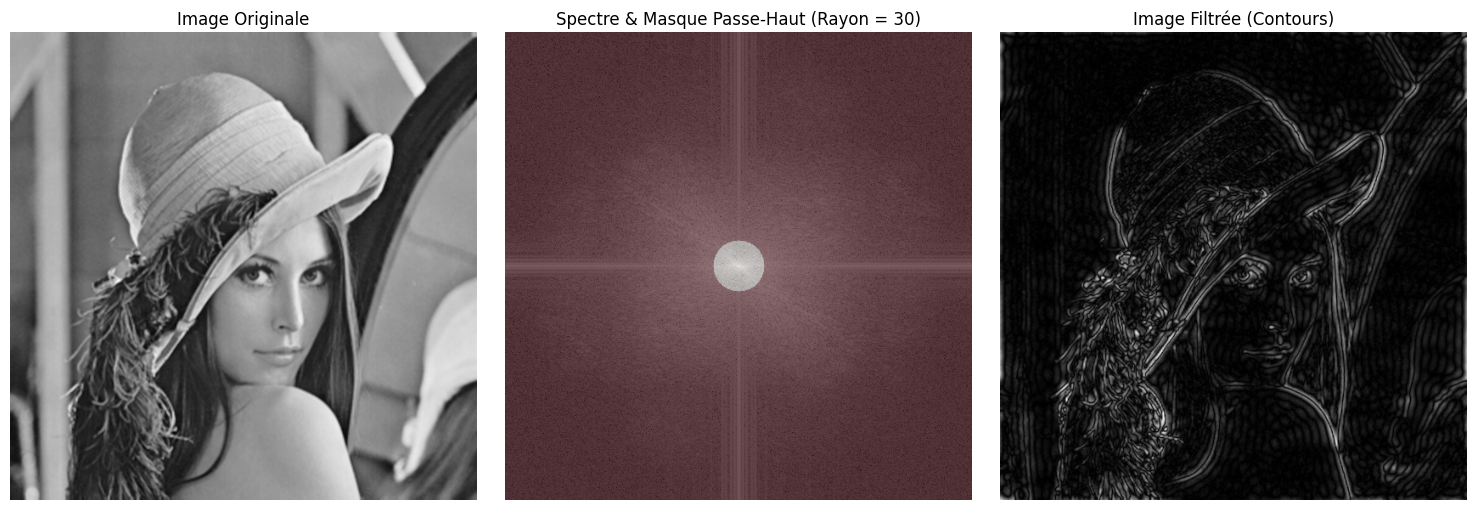

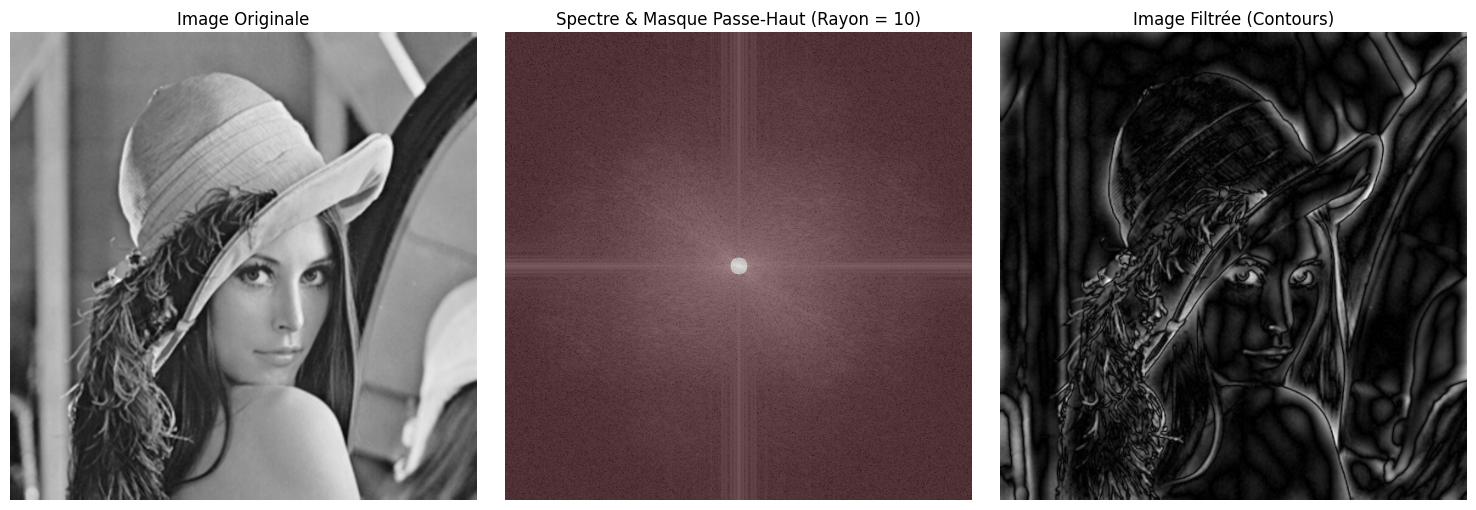

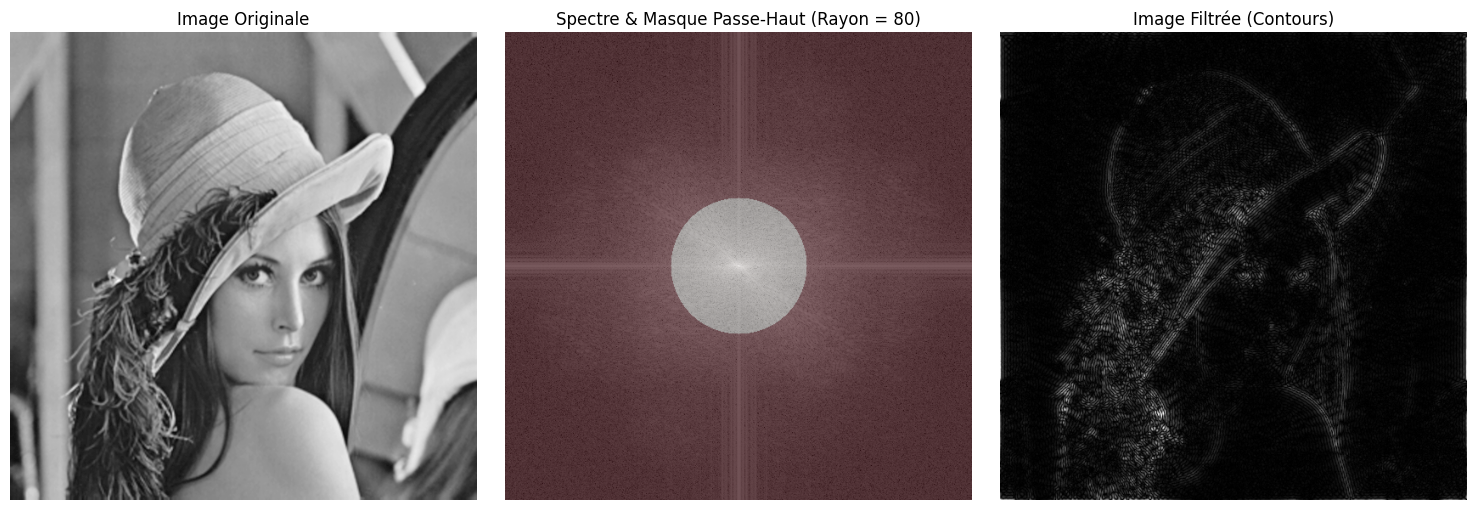

In [159]:
def filtrage_passe_haut_ideal(img, rayon):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    distance_carre = (x - ccol)**2 + (y - crow)**2
    
    masque = np.zeros((rows, cols))
    masque[distance_carre > rayon**2] = 1 
    
    fshift_filtre = fshift * masque
    
    f_ishift = np.fft.ifftshift(fshift_filtre)
    img_filtree = np.abs(np.fft.ifft2(f_ishift))
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('Image Originale')
    axes[0].axis('off')
    
    spectre_magnitude = 20 * np.log(np.abs(fshift) + 1)
    axes[1].imshow(spectre_magnitude, cmap='gray')
    axes[1].imshow(masque, cmap='Reds', alpha=0.3)
    axes[1].set_title(f'Spectre & Masque Passe-Haut (Rayon = {rayon})')
    axes[1].axis('off')
    
    axes[2].imshow(img_filtree, cmap='gray')
    axes[2].set_title('Image Filtrée (Contours)')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

if lena is not None:
    filtrage_passe_haut_ideal(lena, rayon=30)
    filtrage_passe_haut_ideal(lena, rayon=10)
    filtrage_passe_haut_ideal(lena, rayon=80)